# Advanced video retrieval training

This notebook reads the saved results of twelve completed training runs and
sixteen validation policies. Training used 23,202 queries. Evaluation uses all
3,132 eligible validation queries and all 15,927 moments in the validation
corpus. Corpus retrieval metrics are custom; within-video metrics use the
official formula. This is the complete eligible licensed validation population,
not a claim that every video from the original public benchmark was available.

The training curves below are recorded epoch observations, not reconstructed
or simulated runs. No training or test evaluation occurs in this analysis.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').exists())
report = root/'reports/advanced_validation_v1'
raw = (report/'export-manifest.json').read_bytes()
manifest = json.loads(raw)
assert manifest['complete'] and not manifest['test_evaluated']
assert (report/'COMPLETE').read_text().strip() == hashlib.sha256(raw).hexdigest()
for name, pin in manifest['outputs_sha256'].items():
    assert hashlib.sha256((report/name).read_bytes()).hexdigest() == pin
result = json.loads((report/'results.json').read_bytes())
assert result['completed_fits'] == result['required_fits'] == 12
assert len(result['runs']) == 4 and len(result['policies']) == 16
assert result['test_targets_used'] is False
histories, seeds = [], []
for run in result['runs']:
    assert [s['seed'] for s in run['seeds']] == [42, 1337, 2026]
    for seed in run['seeds']:
        history = seed['history']
        assert [h['epoch'] for h in history] == list(range(1, len(history)+1))
        seeds.append(dict(penalty=run['lambda'], seed=seed['seed'],
            completed_epochs=len(history), selected_epoch=seed['best_epoch']))
        histories.extend(dict(penalty=run['lambda'], seed=seed['seed'], **h) for h in history)
history = pd.DataFrame(histories)
display(pd.DataFrame(seeds))
print('Selected policy:', result['selected'])


,penalty,seed,completed_epochs,selected_epoch
0,0.0,42,9,1
1,0.0,1337,10,2
2,0.0,2026,10,2
3,0.5,42,9,1
4,0.5,1337,10,2
5,0.5,2026,9,1
6,1.0,42,9,1
7,1.0,1337,10,2
8,1.0,2026,9,1
9,2.0,42,9,1


Selected policy: frozen_clip


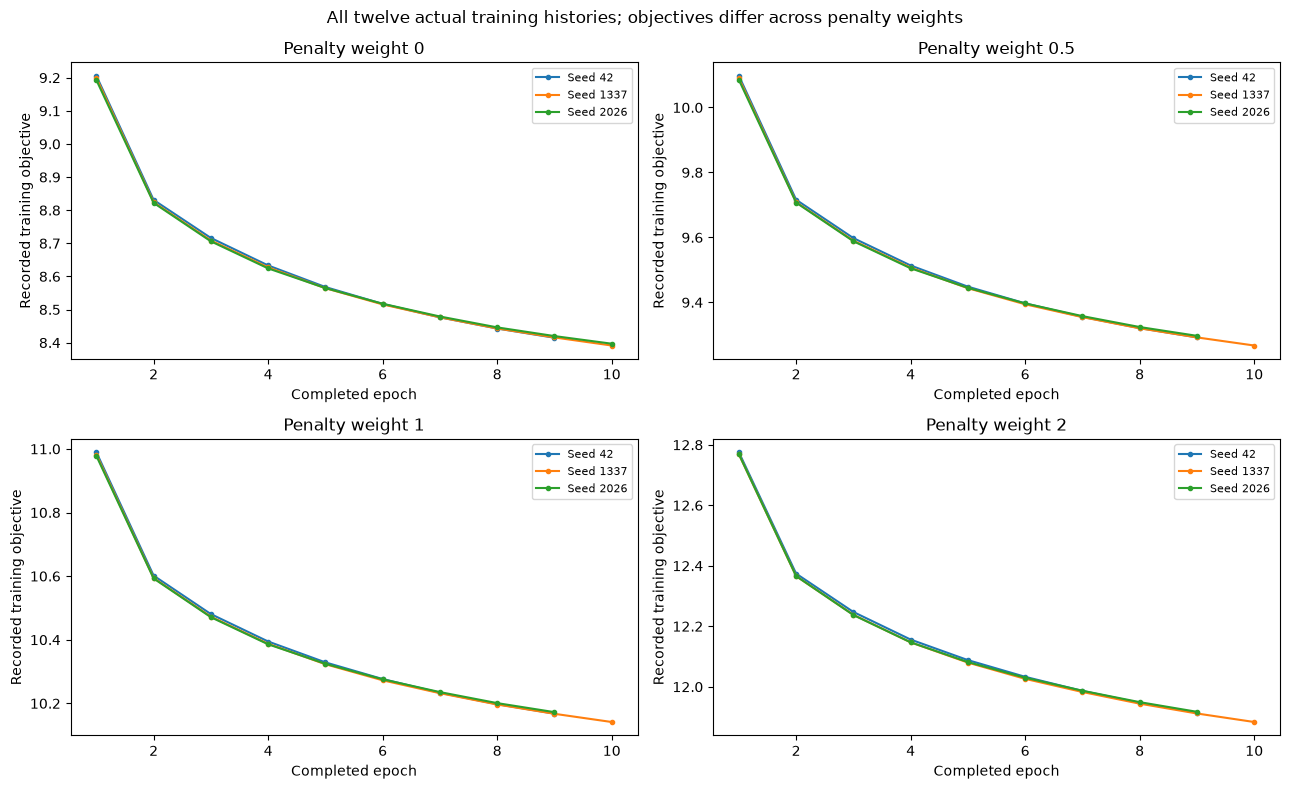

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (penalty, group) in zip(axes.flat, history.groupby('penalty'), strict=True):
    for seed, rows in group.groupby('seed'):
        ax.plot(rows.epoch, rows.train_loss, marker='.', label=f'Seed {seed}')
    ax.set_title(f'Penalty weight {penalty:g}')
    ax.set_xlabel('Completed epoch')
    ax.set_ylabel('Recorded training objective')
    ax.legend(fontsize=8)
fig.suptitle('All twelve actual training histories; objectives differ across penalty weights')
fig.tight_layout()
plt.show()


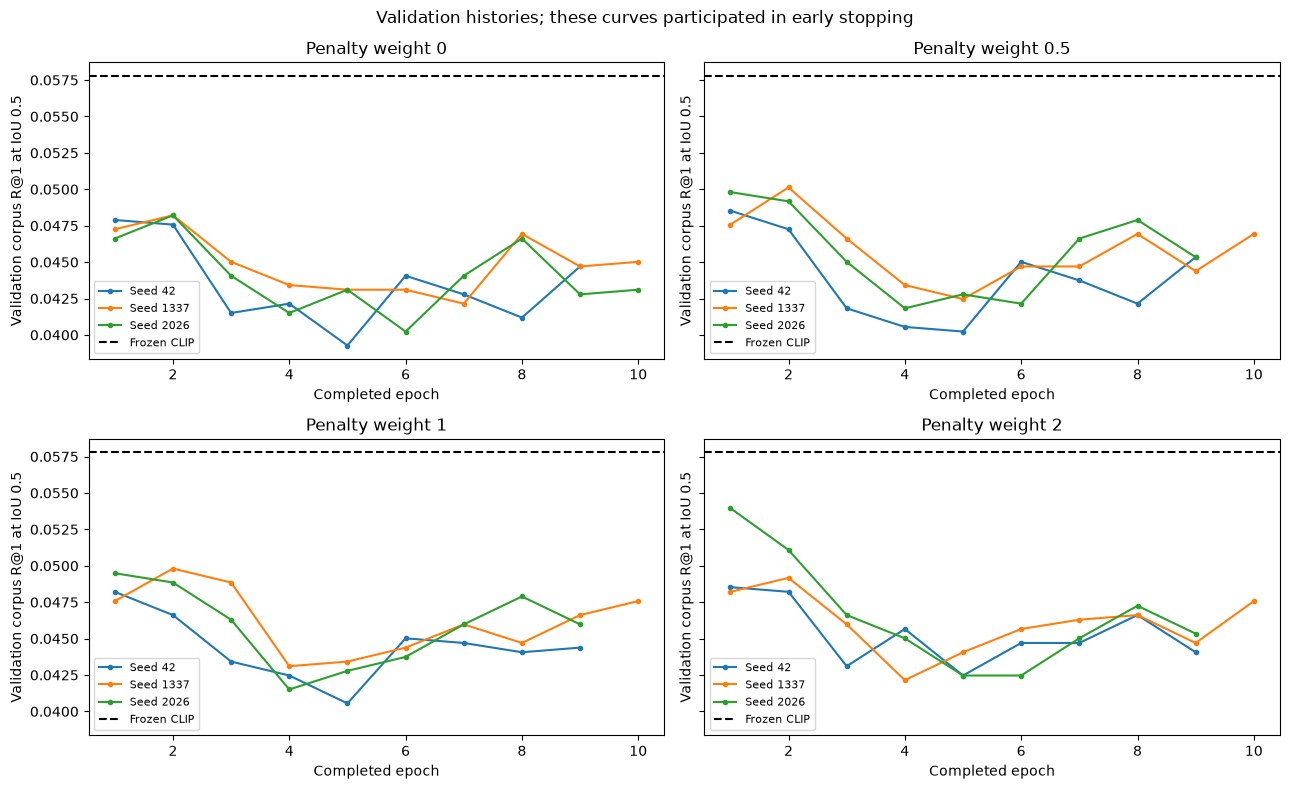

In [3]:
primary = 'corpus_consensus_r1_iou50'
baseline = result['baseline'][primary]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (penalty, group) in zip(axes.flat, history.groupby('penalty'), strict=True):
    for seed, rows in group.groupby('seed'):
        ax.plot(rows.epoch, rows.validation_corpus_consensus_r1_iou50,
                marker='.', label=f'Seed {seed}')
    ax.axhline(baseline, color='black', linestyle='--', label='Frozen CLIP')
    ax.set_title(f'Penalty weight {penalty:g}')
    ax.set_xlabel('Completed epoch')
    ax.set_ylabel('Validation corpus R@1 at IoU 0.5')
    ax.legend(fontsize=8)
fig.suptitle('Validation histories; these curves participated in early stopping')
fig.tight_layout()
plt.show()


,penalty,adapted_weight,corpus_consensus_r1_iou50,corpus_consensus_r5_iou50,within_video_official_rank1,eligible
0,0.0,0.25,0.058110,0.124840,0.154853,False
1,0.0,0.50,0.054598,0.122286,0.164751,False
2,0.0,0.75,0.052363,0.116539,0.172095,False
3,0.0,1.00,0.046935,0.112069,0.176564,False
4,0.5,0.25,0.056194,0.125160,0.156130,False
5,0.5,0.50,0.057471,0.122286,0.165390,False
6,0.5,0.75,0.053640,0.118135,0.172095,False
7,0.5,1.00,0.046935,0.114623,0.175607,False
8,1.0,0.25,0.056513,0.125160,0.156130,False
9,1.0,0.50,0.057791,0.122605,0.166667,False


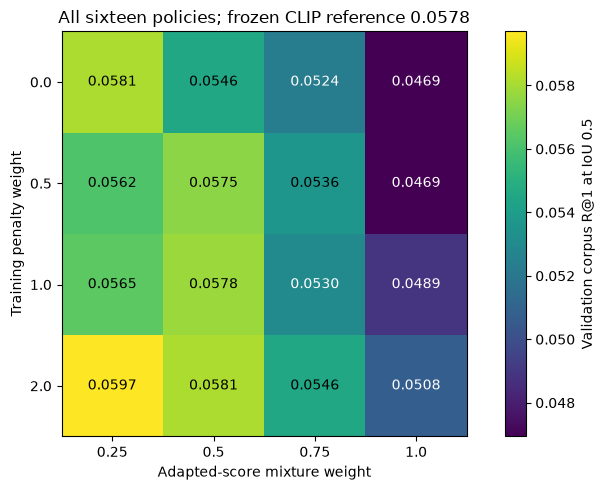

In [4]:
policies = pd.DataFrame([
    dict(penalty=p['lambda'], adapted_weight=p['adapted_score_weight'],
         eligible=p['promotion_eligible'], **p['validation']) for p in result['policies']])
assert policies.queries.eq(3132).all() and policies.candidate_moments.eq(15927).all()
assert not policies.eligible.any() and result['selected'] == 'frozen_clip'
assert result['selected_validation'] == result['baseline']
display(policies[['penalty','adapted_weight',primary,'corpus_consensus_r5_iou50',
                  'within_video_official_rank1','eligible']])
table = policies.pivot(index='penalty', columns='adapted_weight', values=primary)
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(table.to_numpy(), cmap='viridis')
ax.set_xticks(range(4), table.columns)
ax.set_yticks(range(4), table.index)
ax.set_xlabel('Adapted-score mixture weight')
ax.set_ylabel('Training penalty weight')
midpoint = (table.to_numpy().min()+table.to_numpy().max())/2
for i in range(4):
    for j in range(4):
        value = table.iloc[i,j]
        ax.text(j,i,f'{value:.4f}',ha='center',va='center',
                color='black' if value > midpoint else 'white')
fig.colorbar(image, ax=ax, label='Validation corpus R@1 at IoU 0.5')
ax.set_title(f'All sixteen policies; frozen CLIP reference {baseline:.4f}')
fig.tight_layout()
plt.show()


The best mixture improves the primary validation rate by only
about 0.002. It does not meet the registered promotion requirement, so the
selected model remains frozen CLIP. A decreasing training loss alone does not
show improved retrieval.

These figures reproduce saved training and validation summaries. Full dense
score matrices for all sixteen policies have not been independently replayed.
Production parity and the sealed test evaluation are separate deliverables.
